# Plot CEC+SIC buffer trade-off with rock application rate

Top: cumulative CDR by 2100 vs. rock application rate 

Bottom: Share of the scenario's rock target that fits on regional cropland

In [2]:
import os
from pathlib import Path

import cmocean
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from matplotlib.colors import to_rgb

# --- case ---
EXP_GROUP  = "gcam_opr_full2_cec1"
EXP_SET    = "exe_central1p5"
SAVE_GROUP = "gcam"
idx        = "001"

datpath_multiSchedule = (
    f"s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/"
    f"{SAVE_GROUP}/{EXP_GROUP}/{EXP_SET}_{idx}_multiSchedule"
)
dssum = xr.open_zarr(os.path.join(datpath_multiSchedule, EXP_SET, "ds_cdr_globalScaling_constApp_SUM.zarr"))

# global sums (total_dissolution is dissolved rock mass, t)
for var in ["cdr_adv", "cdr_SIConly", "total_dissolution"]:
    if f"{var}_globe" not in dssum:
        dssum[f"{var}_globe"] = dssum[f"{var}_region"].sum("site")

print(f"Apprates:\t {dssum.apprate_base.values}")
print(f"CEC-factors:\t {dssum.cec_factor.values}")
print(f"Dust radii:\t {dssum.dustrad.values}")
print(f"Sites: {len(dssum.site)} | Time steps: {len(dssum.time)}")

SAVE_ON  = True
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/fx-cecSicLimits"
(savehere / "panels").mkdir(parents=True, exist_ok=True)

Apprates:	 [ 0.1   0.25  0.5   1.    2.5   5.   10.   20.   30.  ]
CEC-factors:	 [1.]
spherical radii:	 [ 0.2  0.5  1.   2.5  5.  10.  20.  30. ]
Sites: 32 | Time steps: 80


## Top panel: cumulative CDR by dust radius

- `NORMALIZE_CDR`: `True` plots CDR efficiency (cumulative CDR through 2100 / GCAM's cumulative target, so the target line sits at 1.0). `False` plots absolute cumulative CDR in `CDR_UNITS`.
- Line + points: `cdr_adv`. Ribbon above: `+ cdr_SIConly`.
- `SHOW_DISS_POT`: the CDR the dissolved rock could deliver (`total_dissolution` × `DISS_POT_CO2_PER_T`).

In [5]:
# ============================================================
# USER OPTIONS -- data selection & figure
# ============================================================
CEC_FACTOR       = dssum.cec_factor.values[0]
DUSTRADS_TO_PLOT = [0.2]   # subset of dssum.dustrad.values; one line each
APPRATE_MIN      = 0.1
APPRATE_MAX      = 50

# snap to coordinate values; ascending so the finest radius gets the first color
DUSTRADS_TO_PLOT = np.sort(dssum.dustrad.sel(
    dustrad=np.atleast_1d(np.asarray(DUSTRADS_TO_PLOT, dtype=float)), method="nearest"
).values)

# --- y-axis: CDR efficiency (True) or absolute cumulative CDR in CDR_UNITS (False) ---
NORMALIZE_CDR = True
CDR_UNITS     = "GtCO2"   # "t", "MtCO2", or "GtCO2"
_UNIT_SCALE   = {"t": 1.0, "MtCO2": 1e-6, "GtCO2": 1e-9}
_UNIT_LABEL   = {"t": "t CO$_2$", "MtCO2": "Mt CO$_2$", "GtCO2": "Gt CO$_2$"}

# --- figure ---
FIGSIZE             = (12.5, 9.5)
DPI                 = 300
LINEWIDTH           = 3.5    # every line in both panels
MARKER              = "o"
MARKERSIZE          = 18
FONTSIZE_LABEL      = 25
FONTSIZE_TICK       = 23
FONTSIZE_TITLE      = 25
FONTSIZE_LEGEND     = 23
LOG_X               = True
LOG_Y               = False
SHOW_GRID           = False
TITLE               = None   # None = auto from NORMALIZE_CDR
YLABEL_TOP          = None   # None = auto from NORMALIZE_CDR / CDR_UNITS
YLIM_TOP            = (0, 1.1)
XLABEL              = "Application flux (t ha$^{-1}$ yr$^{-1}$)"
XLIM                = (APPRATE_MIN, 30)
LEGEND_TITLE        = "Dust radius (μm)"
ADD_LEGEND_CUMCDR   = False
ADD_LEGEND_CROPLAND = False

# --- overlays ---
SHOW_TARGET        = True
TARGET_LABEL       = "GCAM target"
SHOW_SICONLY       = True    # cdr_adv -> cdr_adv + cdr_SIConly ribbon
SICONLY_FILL_ALPHA = 0.2
SHOW_DISS_POT      = True
DISS_POT_CO2_PER_T = 0.3     # t CO2 per t rock dissolved, as in fig-bestCdrCurves.ipynb
DISS_POT_LABEL     = "{dr:g} (diss. potential)"

# --- colors: CarbonPlan light-mode palette (carbonplan.org/design/color), else cmocean + hex ---
USE_CARBONPLAN_COLORS = True
CP = {
    "primary": "#1b1e23", "secondary": "#808080", "muted": "#b0afb1",
    "red": "#f07071", "orange": "#ea9755", "yellow": "#d4c05e", "green": "#7eb36a",
    "teal": "#64b9c4", "blue": "#85a2f7", "purple": "#bc85d9", "pink": "#e587b6", "grey": "#a9b4c4",
}
if USE_CARBONPLAN_COLORS:
    _cycle           = ["primary", "blue", "purple", "pink"]
    PALETTE          = [CP[_cycle[i % len(_cycle)]] for i in range(len(DUSTRADS_TO_PLOT))]
    TARGET_COLOR     = CP["secondary"]
    LAND_LINE_COLOR  = LAND_FILL_COLOR = CP["green"]
    LAND_ALPHA_RANGE = (0.4, 0.2)
    TEXT_COLOR       = CP["primary"]
else:
    PALETTE          = [cmocean.cm.rain_r(x) for x in np.linspace(0.1, 0.8, len(DUSTRADS_TO_PLOT))]
    TARGET_COLOR     = "#898781"
    LAND_LINE_COLOR, LAND_FILL_COLOR = "#1b5e36", "#2e8b57"
    LAND_ALPHA_RANGE = (0.25, 0.1)
    TEXT_COLOR       = "black"

print(f"Plotting dust radii: {DUSTRADS_TO_PLOT} | cec_factor: {CEC_FACTOR}")

Plotting dust radii: [0.2] | cec_factor: 1.0


In [6]:
# --- top-panel data: cumulative CDR through 2100, as CDR efficiency or in CDR_UNITS ---
_sel = dict(cec_factor=CEC_FACTOR, apprate_base=slice(APPRATE_MIN, APPRATE_MAX))

# GCAM cumulative target (t CO2); apprate- and dustrad-independent
target_cumulative = float(
    dssum["gcam_cdr_globe"]
    .sel(dustrad=DUSTRADS_TO_PLOT[0], **_sel)
    .sum(dim="time")
    .mean(dim="apprate_base")
)
_y_scale  = (1.0 / target_cumulative) if NORMALIZE_CDR else _UNIT_SCALE[CDR_UNITS]
_target_y = target_cumulative * _y_scale

cdr_adv_ts     = dssum["cdr_adv_globe"].sel(dustrad=DUSTRADS_TO_PLOT, **_sel)
cdr_siconly_ts = dssum["cdr_SIConly_globe"].sel(dustrad=DUSTRADS_TO_PLOT, **_sel)
diss_pot_ts    = dssum["total_dissolution_globe"].sel(dustrad=DUSTRADS_TO_PLOT, **_sel)

cdr_top       = cdr_adv_ts.sum(dim="time") * _y_scale   # (apprate_base, dustrad)
cdr_total_top = (cdr_adv_ts + cdr_siconly_ts).sum(dim="time") * _y_scale
diss_pot_top  = diss_pot_ts.sum(dim="time") * DISS_POT_CO2_PER_T * _y_scale

_ylabel_top = YLABEL_TOP if YLABEL_TOP is not None else (
    "CDR efficiency" if NORMALIZE_CDR else f"Cumulative CDR by 2100 ({_UNIT_LABEL[CDR_UNITS]})"
)
_title_top = TITLE if TITLE is not None else (
    "CDR efficiency vs. application flux" if NORMALIZE_CDR else "Cumulative CDR by 2100 vs. application flux"
)

print(f"GCAM target: {target_cumulative * 1e-9:.1f} Gt CO2 by 2100 -> y = {_target_y:g}")
print(f"peak -- cdr_adv: {float(cdr_top.max()):.2f} | + SIC: {float(cdr_total_top.max()):.2f}"
      f" | diss. potential: {float(diss_pot_top.max()):.2f}")

Top-panel y-axis: normalized (fraction of GCAM target)
GCAM target: 279.9 Gt CO2 cumulative by 2100 -> plotted at y = 1
peak -- cdr_adv: 0.64 | cdr_adv + SIC: 0.64 | dissolution potential: 0.92


## Bottom panel: feasible rock application

Share of each scenario's rock-mass target that fits on regional cropland at each application rate, counting partial fits and weighting regions by their time-integrated target.

- `LAND_GCAM_SCENARIOS`: required cropland from the `gcam/apprate_calculated/one-cell-per-region/{scen}` pkl + zarr.
- `LAND_CURVES`: `cropfrac_ERW` from the `_multiSchedule` SCEPTER runs. Check the names still exist if `EXP_GROUP` changes.

In [7]:
# ============================================================
# USER OPTIONS -- bottom panel
# ============================================================
LAND_GCAM_SCENARIOS   = ["exe_central1p5"]                           # GCAM exe_* scenarios
LAND_CURVES           = ["nearterm-gcam-first10yrs_k_gcam_L0.5Gt"]   # synthetic S-curves (_multiSchedule runs)
LAND_SCENARIOS        = LAND_GCAM_SCENARIOS + LAND_CURVES            # plot order; fill alphas ramp along it
LAND_PRIMARY_SCENARIO = EXP_SET   # full-strength line; others lightened
LAND_LINE_LIGHTEN     = 0.5       # blend of non-primary lines toward white
LAND_YEAR             = 2100
LAND_REF_APPRATE      = 5.0       # any precomputed rate; the mass target is apprate-independent
LAND_DEG_RES          = 1
LAND_APPRATE_N        = 200       # log-spaced points across APPRATE_MIN..APPRATE_MAX

LAND_LABELS = {   # unlisted scenarios use their raw name
    "exe_central1p5":             "Central 1.5°C",
    "exe_noWeathering1p5":        "High cost 1.5°C",
    "exe_techBehaviorChange1p5":  "Tech+behavior 1.5°C",
    "scurve_0.5Gt_early_sameMax": "0.5 Gt max",
    "scurve_1.0Gt_early_sameMax": "1.0 Gt max",
    "scurve_2.0Gt_early_sameMax": "2.0 Gt max",
}

ROCKFIT_YLIM      = (0, 105)
ROCKFIT_YTICKS    = [0, 50, 100]
ROCKFIT_YLABEL    = "Feasible rock\napplication (%)"
ROCKFIT_MARK_PEAK = False   # vertical guide at the CDR peak

LAND_ALPHAS = (
    [float(np.mean(LAND_ALPHA_RANGE))] if len(LAND_SCENARIOS) == 1
    else list(np.linspace(*LAND_ALPHA_RANGE, len(LAND_SCENARIOS)))
)

In [8]:
# --- bottom-panel data: % of each scenario's rock target that fits on regional cropland ---
_land_gcam_fn_df = f"annual_rockflx_densest-ag-region_{LAND_DEG_RES}deg.pkl"
_land_gcam_fn    = f"cropland+gcamRegions_time_{LAND_DEG_RES}deg.zarr"

_land_mass_t_yr  = {}   # {scen: DataFrame(time x reg_id)}
_land_area_ha    = {}   # {scen: array(reg_id)}
_regid_to_region = {}   # reg_id -> dssum `site` label

for scen in LAND_GCAM_SCENARIOS:
    land_dir = (
        f"s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/"
        f"one-cell-per-region/{scen}/{LAND_REF_APPRATE}-tHaYr-appRate-FIXED"
    )
    df_ref = pd.read_pickle(os.path.join(land_dir, _land_gcam_fn_df))
    ds_ref = xr.open_zarr(os.path.join(land_dir, _land_gcam_fn))

    # required area x apprate = rock-mass target (t/yr) at any reference apprate
    _land_mass_t_yr[scen] = df_ref.pivot(index="time", columns="reg_id", values="cropland_area_required_ha") * LAND_REF_APPRATE
    _regid_to_region.update(df_ref[["reg_id", "region_nospaces"]].drop_duplicates().values)

    reg_id_grid = ds_ref["reg_id"].values
    cropland_ha = (ds_ref["cropland_area"].values / 1e4).flatten()   # m^2 -> ha
    reg_id_flat = reg_id_grid.flatten()
    reg_ids     = _land_mass_t_yr[scen].columns.values
    _land_area_ha[scen] = np.array([np.nansum(cropland_ha[reg_id_flat == rid]) for rid in reg_ids])


def frac_req_all_regions_gcam(scen, app_rates, year=LAND_YEAR):
    """Required-cropland fraction by region, GCAM scenario."""
    mass_at_year = _land_mass_t_yr[scen].loc[year]
    area_ha      = pd.Series(_land_area_ha[scen], index=_land_mass_t_yr[scen].columns)
    frac_req     = mass_at_year.values[None, :] / (np.asarray(app_rates)[:, None] * area_ha.values[None, :])
    regions      = [_regid_to_region[rid] for rid in mass_at_year.index.values]
    return xr.DataArray(frac_req, dims=("apprate_base", "region"), coords={"apprate_base": app_rates, "region": regions})


def frac_req_all_regions_scepter(curve_name, app_rates, ref_apprate=LAND_REF_APPRATE):
    """Required-cropland fraction by region, synthetic S-curve (cropfrac_ERW x apprate is constant per site)."""
    curve_dir = os.path.join(datpath_multiSchedule, curve_name, "ds_cdr_globalScaling_constApp_SUM.zarr")
    ds_curve  = xr.open_zarr(curve_dir)
    dustrad0  = float(ds_curve.dustrad.values[0])      # cropfrac_ERW is dustrad- and cec_factor-independent
    cec0      = float(ds_curve.cec_factor.values[0])
    cf_ref = (
        ds_curve["cropfrac_ERW"]
        .sel(dustrad=dustrad0, cec_factor=cec0, apprate_base=ref_apprate, method="nearest")
        .isel(time=-1)   # ~2100
        .compute()
    )
    apprate_ref = float(ds_curve.apprate_base.sel(apprate_base=ref_apprate, method="nearest"))
    K = cf_ref.values * apprate_ref
    frac_req = K[None, :] / np.asarray(app_rates)[:, None]
    return xr.DataArray(frac_req, dims=("apprate_base", "region"), coords={"apprate_base": app_rates, "region": ds_curve.site.values})


def rockfit_weights(scen):
    """Time-integrated regional target: pkl rock mass (GCAM scenarios) or gcam_cdr (synthetic curves)."""
    if scen in LAND_GCAM_SCENARIOS:
        m = _land_mass_t_yr[scen].sum()
        return xr.DataArray(m.values, dims="region", coords={"region": [_regid_to_region[r] for r in m.index]})
    ds_curve = xr.open_zarr(os.path.join(datpath_multiSchedule, scen, "ds_cdr_globalScaling_constApp_SUM.zarr"))
    return ds_curve["gcam_cdr"].isel(apprate_base=0, dustrad=0, cec_factor=0).sum("time").rename(site="region").compute()


land_apprate_grid = np.geomspace(APPRATE_MIN, APPRATE_MAX, LAND_APPRATE_N)
frac_req_by_scen  = {
    **{scen: frac_req_all_regions_gcam(scen, land_apprate_grid) for scen in LAND_GCAM_SCENARIOS},
    **{curve: frac_req_all_regions_scepter(curve, land_apprate_grid) for curve in LAND_CURVES},
}

# partial fits count: a region needing 150% of its cropland still holds 2/3 of its rock
rockfit_by_scen = {}
for scen in LAND_SCENARIOS:
    fr = frac_req_by_scen[scen]
    w  = rockfit_weights(scen).sel(region=fr.region)
    rockfit_by_scen[scen] = (w * (1 / np.maximum(1, fr))).sum("region") / w.sum() * 100

_x_peak = float(cdr_top.sel(dustrad=DUSTRADS_TO_PLOT[0]).idxmax("apprate_base"))
for scen in LAND_SCENARIOS:
    _h = rockfit_by_scen[scen].values
    _x_all = float((frac_req_by_scen[scen].isel(apprate_base=0) * land_apprate_grid[0]).max())
    print(f"{LAND_LABELS.get(scen, scen):>22}: {np.interp(_x_peak, land_apprate_grid, _h):.0f}% fits at the {_x_peak:g} t/ha/yr peak | "
          f"50% / 90% / 100% fits at {np.interp(50, _h, land_apprate_grid):.1f} / {np.interp(90, _h, land_apprate_grid):.1f} / {_x_all:.1f} t/ha/yr")

         Central 1.5°C: 21% fits at the 2.5 t/ha/yr peak | 50% / 90% / 100% fits at 7.1 / 17.7 / 30.0 t/ha/yr
nearterm-gcam-first10yrs_k_gcam_L0.5Gt: 98% fits at the 2.5 t/ha/yr peak | 50% / 90% / 100% fits at 0.8 / 1.9 / 3.2 t/ha/yr


## Plot

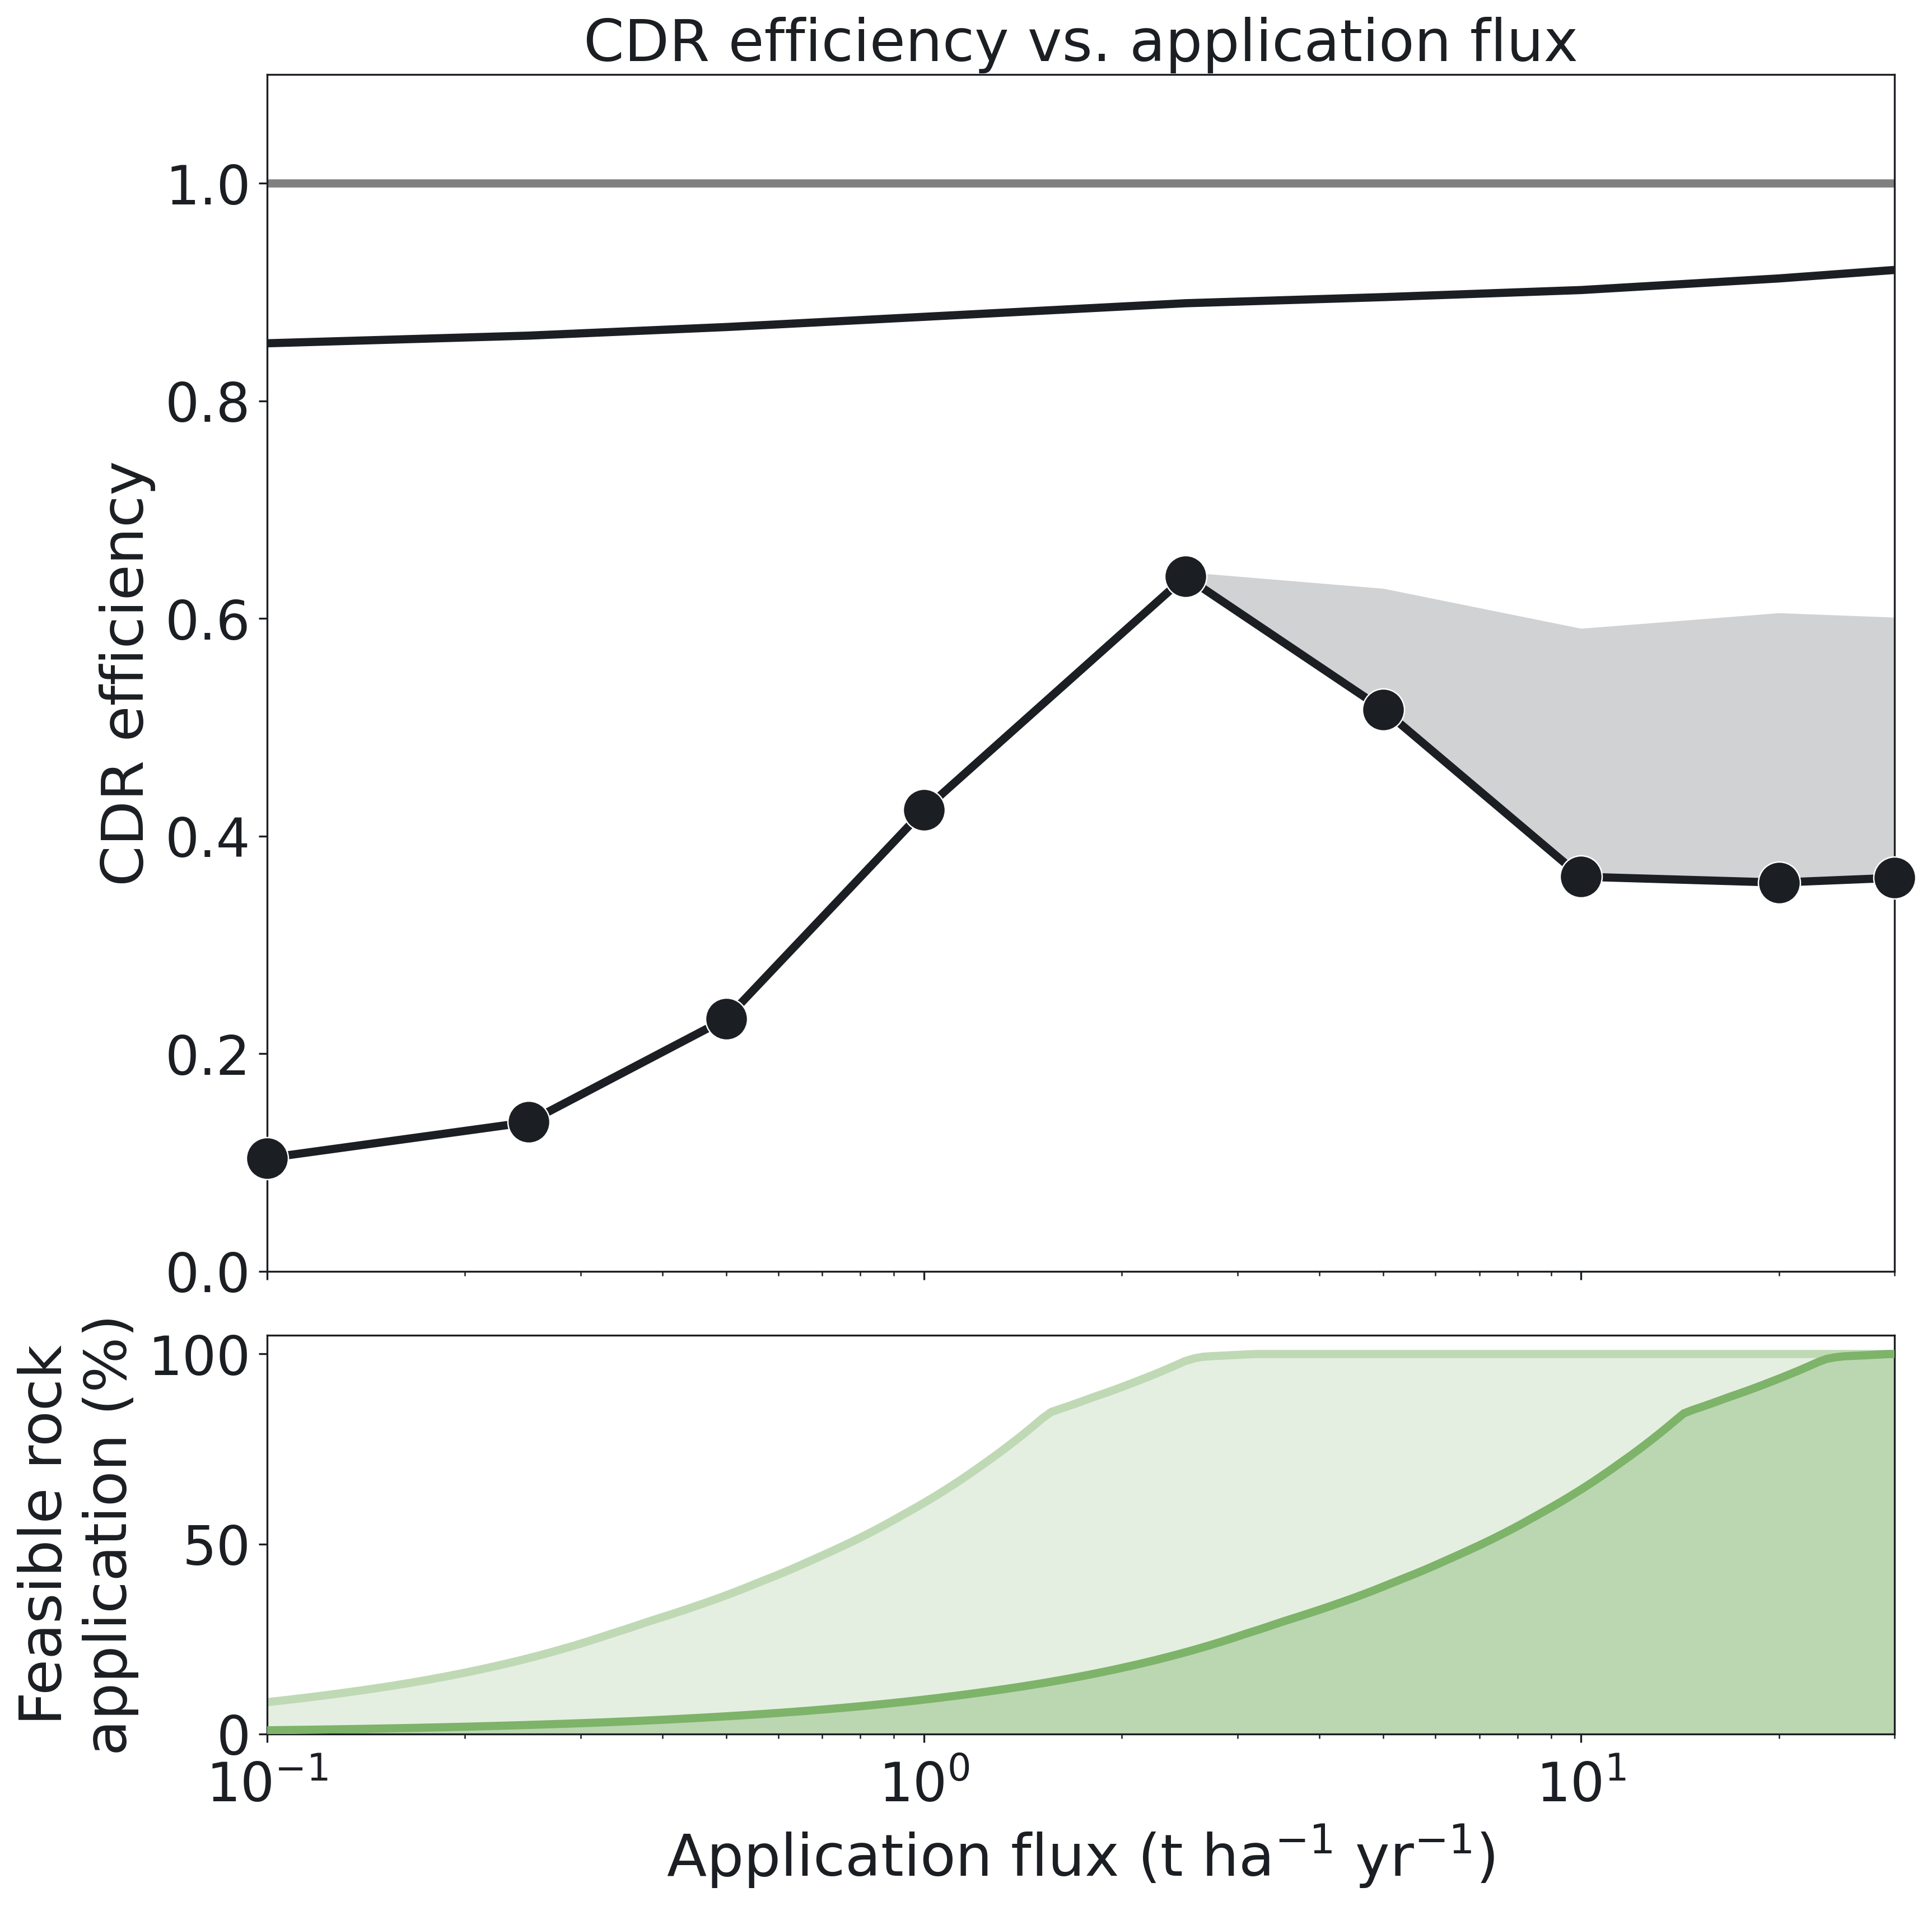

In [9]:
# [ PLOT: cumulative CDR / CDR efficiency (top) + feasible rock application (bottom), shared x-axis ] —
_stroke = dict(lw=LINEWIDTH, ls="-", alpha=1.0, solid_capstyle="round", solid_joinstyle="round")
_xsel   = dict(apprate_base=slice(*XLIM))   # keeps the unclipped CDR line inside the axes


def _lighten(c, f):
    return tuple((1 - f) * np.asarray(to_rgb(c)) + f)


fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(FIGSIZE[0], FIGSIZE[1] * 1.35), dpi=DPI, sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08},
)

# fills below lines; finest radius on top within each
_dustrad_desc = sorted(DUSTRADS_TO_PLOT, reverse=True)
_fill_zorder  = {dr: 1 + rank for rank, dr in enumerate(_dustrad_desc)}
_line_zorder  = {dr: 10 + rank for rank, dr in enumerate(_dustrad_desc)}

# --- top ---
if SHOW_TARGET:
    ax_top.axhline(_target_y, color=TARGET_COLOR, label=TARGET_LABEL, zorder=0, **_stroke)

for i, dr in enumerate(DUSTRADS_TO_PLOT):
    y = cdr_top.sel(dustrad=dr, **_xsel)
    ax_top.plot(
        y.apprate_base, y, color=PALETTE[i], marker=MARKER, markersize=MARKERSIZE,
        markeredgecolor="white", markeredgewidth=0.6,
        clip_on=False,   # edge markers draw over the spines instead of being cut in half
        label=f"{dr:g}", zorder=_line_zorder[dr], **_stroke,
    )

if SHOW_SICONLY:
    for i, dr in enumerate(DUSTRADS_TO_PLOT):
        y_adv   = cdr_top.sel(dustrad=dr, **_xsel)
        y_total = cdr_total_top.sel(dustrad=dr, **_xsel)
        ax_top.fill_between(
            y_adv.apprate_base, y_adv, y_total,
            color=PALETTE[i], alpha=SICONLY_FILL_ALPHA, linewidth=0, zorder=_fill_zorder[dr],
        )

if SHOW_DISS_POT:
    for i, dr in enumerate(DUSTRADS_TO_PLOT):
        y = diss_pot_top.sel(dustrad=dr, **_xsel)
        ax_top.plot(
            y.apprate_base, y, color=PALETTE[i],
            label=DISS_POT_LABEL.format(dr=dr), zorder=_line_zorder[dr], **_stroke,
        )

if LOG_X:
    ax_top.set_xscale("log")
if LOG_Y:
    ax_top.set_yscale("log")
if YLIM_TOP is not None:
    ax_top.set_ylim(*YLIM_TOP)

ax_top.set_ylabel(_ylabel_top, fontsize=FONTSIZE_LABEL)
ax_top.set_title(_title_top, fontsize=FONTSIZE_TITLE)
ax_top.tick_params(labelsize=FONTSIZE_TICK)
plt.setp(ax_top.get_xticklabels(), visible=False)

if SHOW_GRID:
    ax_top.grid(True, which="major", color="#e1e0d9", linewidth=0.8, zorder=0)
    ax_top.set_axisbelow(True)
if ADD_LEGEND_CUMCDR:
    ax_top.legend(
        title=LEGEND_TITLE, fontsize=FONTSIZE_LEGEND, title_fontsize=FONTSIZE_LEGEND,
        frameon=False, loc="best",
    )

# --- bottom ---
for scen, alpha in zip(LAND_SCENARIOS, LAND_ALPHAS):
    ax_bot.fill_between(
        land_apprate_grid, 0, rockfit_by_scen[scen],
        color=LAND_FILL_COLOR, alpha=alpha, linewidth=0, zorder=1,
    )

for scen in LAND_SCENARIOS:
    is_primary = (scen == LAND_PRIMARY_SCENARIO)
    ax_bot.plot(
        land_apprate_grid, rockfit_by_scen[scen],
        color=LAND_LINE_COLOR if is_primary else _lighten(LAND_LINE_COLOR, LAND_LINE_LIGHTEN),
        zorder=3 if is_primary else 2,
        label=LAND_LABELS.get(scen, scen), **_stroke,
    )

if ROCKFIT_MARK_PEAK:
    for _ax in (ax_top, ax_bot):
        _ax.axvline(_x_peak, color=TARGET_COLOR, zorder=0, **_stroke)

ax_bot.set_ylim(*ROCKFIT_YLIM)
ax_bot.set_yticks(ROCKFIT_YTICKS)
ax_bot.set_xlabel(XLABEL, fontsize=FONTSIZE_LABEL)
ax_bot.set_ylabel(ROCKFIT_YLABEL, fontsize=FONTSIZE_LABEL)
ax_bot.tick_params(labelsize=FONTSIZE_TICK)
ax_bot.tick_params(axis="x", pad=8)
if ADD_LEGEND_CROPLAND:
    ax_bot.legend(fontsize=FONTSIZE_LEGEND, frameon=False, title="", title_fontsize=FONTSIZE_LEGEND)

for _ax in (ax_top, ax_bot):
    _ax.tick_params(which="both", colors=TEXT_COLOR)
    _ax.spines[:].set_color(TEXT_COLOR)
    for _t in (_ax.title, _ax.xaxis.label, _ax.yaxis.label):
        _t.set_color(TEXT_COLOR)

ax_top.set_xlim(*XLIM)

plt.show()

if SAVE_ON:
    fname = "cdr-lines-by-apprate.png"
    fig.savefig(os.path.join(savehere, "panels", fname), dpi=300, bbox_inches="tight", transparent=False)